# 03services: everyday services from OpenStreetMap (Stage 2, part 1 of 4)

Klang Valley Reach and Risk, Stage 2: access to services.

This notebook collects the five kinds of services and turns each one into points that a person can walk to.

| Category | Source |
|---|---|
| healthcare | OSM: clinics, hospitals, doctors |
| school | OSM: schools |
| park | OSM: parks and playgrounds |
| grocery | OSM: supermarkets, markets, greengrocers (convenience stores optional) |
| rail | Project 1 files: Rapid Rail and KTM Komuter stations |

- Input: `districts.geojson`, `stations.geojson`, `komuter_stations.geojson`, and OpenStreetMap (downloaded here)
- Output: `data/raw/osm_tiles/` (one file per tile, so re-runs continue where they stopped), `data/raw/osm_services_raw.parquet`, `data/processed/services.parquet`
- Next: `04walknetwork.ipynb`

## Section 0: settings

In [ ]:
from pathlib import Path

BASE = Path.cwd()
RAW = BASE / "data" / "raw"
PROCESSED = BASE / "data" / "processed"
OUTPUT = BASE / "output"
SERVICES_FILE = PROCESSED / "services.parquet"

BUFFER_M = 2000        # also collect services up to 2 km outside the Klang Valley edge, so hexagons near the boundary are not punished for it
METRIC_CRS = 32647     # UTM zone 47N, metres (for buffers and distances)
PARK_SPACING_M = 100   # parks become points every 100 m along their edge (people enter from the side)
INCLUDE_CONVENIENCE = False   # True also counts convenience stores (7-Eleven, mini markets) as groceries
REDOWNLOAD = False     # True ignores the saved tiles and downloads everything again

# Download in small tiles, so progress is visible and a failure only costs one tile
TILE_DEG = 0.1         # tile size in degrees (0.1 = about 11 km)
TILE_DIR = RAW / "osm_tiles"
RAW_FILE = RAW / "osm_services_raw.parquet"
TIMEOUT_S = 90         # give up on one request after 90 s and try the next server
OVERPASS_SERVERS = [   # tried in this order; servers that do not answer are skipped
    "https://overpass-api.de/api",
    "https://overpass.private.coffee/api",
    "https://maps.mail.ru/osm/tools/overpass/api",
    "https://overpass.kumi.systems/api",
]

# OpenStreetMap tags for each category (key: list of values)
OSM_TAGS = {
    "healthcare": {"amenity": ["clinic", "hospital", "doctors"],
                   "healthcare": ["clinic", "hospital", "doctor", "centre"]},
    "school":     {"amenity": ["school"]},
    "park":       {"leisure": ["park", "playground"]},
    "grocery":    {"shop": ["supermarket", "greengrocer", "convenience"],
                   "amenity": ["marketplace"]},
}

In [2]:
import pandas as pd
import geopandas as gpd
import osmnx as ox
from shapely.geometry import Point

ox.settings.use_cache = True                  # OSMnx keeps a copy of every answer in KL2/cache
ox.settings.cache_folder = str(BASE / "cache")
ox.settings.requests_timeout = TIMEOUT_S
ox.settings.overpass_rate_limit = False       # we pause ourselves between tiles
ox.settings.log_console = False
print("osmnx", ox.__version__)

osmnx 2.1.1


## Step 1: the area to search

The seven districts joined into one shape, plus a 2 km margin.

In [3]:
districts = gpd.read_file(PROCESSED / "districts.geojson").to_crs(4326)
area_m = districts.to_crs(METRIC_CRS).union_all().buffer(BUFFER_M)
area = gpd.GeoSeries([area_m], crs=METRIC_CRS).to_crs(4326).iloc[0]
print("Search area: %.0f km2" % (area_m.area / 1e6))

Search area: 4294 km2


## Step 2: download from OpenStreetMap, tile by tile

- The search area is cut into small tiles (about 11 km wide). Each tile is one request for **all four** service types.
- A progress line shows how many tiles are done and roughly how long is left.
- Every finished tile is saved in `data/raw/osm_tiles`. If the run stops, just run this cell again: it continues
  with the missing tiles only.
- If a server does not answer, the next one in `OVERPASS_SERVERS` is tried.

In [4]:
import time
import requests
from shapely.geometry import box
from IPython.display import display, HTML

# 2a. Which servers answer right now?
def server_ok(url):
    try:
        requests.get(url.rstrip("/") + "/status", timeout=10)   # any reply means the server is reachable
        return True
    except requests.RequestException:
        return False

servers = [u for u in OVERPASS_SERVERS if server_ok(u)]
for u in OVERPASS_SERVERS:
    print(("OK      " if u in servers else "no reply"), u)
assert servers, "No Overpass server answered. Check your internet connection, or try again later."

# 2b. Cut the search area into tiles
minx, miny, maxx, maxy = area.bounds
tiles = []
x = minx
while x < maxx:
    y = miny
    while y < maxy:
        t = box(x, y, min(x + TILE_DEG, maxx), min(y + TILE_DEG, maxy)).intersection(area)
        if not t.is_empty and t.area > 0:
            tiles.append(t)
        y += TILE_DEG
    x += TILE_DEG
TILE_DIR.mkdir(parents=True, exist_ok=True)
print(len(tiles), "tiles")

OK       https://overpass-api.de/api
OK       https://overpass.private.coffee/api
OK       https://maps.mail.ru/osm/tools/overpass/api
OK       https://overpass.kumi.systems/api
54 tiles


In [5]:
# 2c. Download the tiles (re-run this cell if it stops; finished tiles are skipped)
ALL_TAGS = {}
for tags in OSM_TAGS.values():
    for key, values in tags.items():
        ALL_TAGS.setdefault(key, [])
        ALL_TAGS[key] += [v for v in values if v not in ALL_TAGS[key]]

KEEP = ["name", "amenity", "healthcare", "shop", "leisure", "access", "geometry"]

def get_tile(polygon):
    """Try each working server in turn; return a GeoDataFrame (empty if the tile has nothing)."""
    last_error = None
    for url in list(servers):
        ox.settings.overpass_url = url
        try:
            gdf = ox.features_from_polygon(polygon, ALL_TAGS).reset_index()
            return gdf[[c for c in ["element", "id"] + KEEP if c in gdf.columns]]
        except ox._errors.InsufficientResponseError:
            return gpd.GeoDataFrame(columns=["element", "id", "geometry"], geometry="geometry", crs=4326)
        except Exception as e:          # timeout, connection refused, server error: try the next server
            last_error = e
            servers.remove(url)         # and move this server to the back of the queue for later tiles
            servers.append(url)
    raise RuntimeError(f"all servers failed: {type(last_error).__name__}")

def bar(done, total, width=30):
    n = int(width * done / total)
    return "[" + "#" * n + "-" * (width - n) + "]"

progress = display(HTML("<pre>starting ...</pre>"), display_id=True)
start = time.time()
fetched, failed = 0, []
for i, t in enumerate(tiles):
    f = TILE_DIR / f"tile_{i:03d}.parquet"
    if f.exists() and not REDOWNLOAD:
        continue
    try:
        get_tile(t).to_parquet(f, index=False)
        fetched += 1
    except RuntimeError as e:
        failed.append(i)
    done = sum((TILE_DIR / f"tile_{k:03d}.parquet").exists() for k in range(len(tiles)))
    mins = (time.time() - start) / 60
    left = mins / max(fetched, 1) * (len(tiles) - done)
    progress.update(HTML(f"<pre>{bar(done, len(tiles))} {done}/{len(tiles)} tiles ({100 * done / len(tiles):.0f}%) | "
                         f"{mins:.1f} min so far, about {left:.0f} min left | failed: {len(failed)}</pre>"))
    time.sleep(1)                       # be polite to the free servers

done = sum((TILE_DIR / f"tile_{k:03d}.parquet").exists() for k in range(len(tiles)))
progress.update(HTML(f"<pre>{bar(done, len(tiles))} {done}/{len(tiles)} tiles done in {(time.time() - start) / 60:.1f} min</pre>"))
if failed:
    raise RuntimeError(f"{len(failed)} tiles failed ({failed}). Run this cell again to fetch only those.")
print("All tiles downloaded.")

All tiles downloaded.


In [6]:
# 2d. Join the tiles, remove features that appear in two tiles, sort into categories
parts = [gpd.read_parquet(TILE_DIR / f"tile_{k:03d}.parquet") for k in range(len(tiles))]
osm = gpd.GeoDataFrame(pd.concat([p for p in parts if len(p)], ignore_index=True), crs=4326)
osm = osm.drop_duplicates(["element", "id"]).reset_index(drop=True)
osm.to_parquet(RAW_FILE, index=False)
print(f"{len(osm):,} features saved to {RAW_FILE.name}")

def col(gdf, name):
    return gdf[name] if name in gdf.columns else pd.Series(pd.NA, index=gdf.index)

raw = {}
for cat, tags in OSM_TAGS.items():
    mask = pd.Series(False, index=osm.index)
    for key, values in tags.items():
        mask |= col(osm, key).isin(values)
    raw[cat] = osm[mask].copy()
    raw[cat]["category"] = cat

for cat, gdf in raw.items():
    print(f"{cat:11s} {len(gdf):6,d} features | by type:", gdf["element"].value_counts().to_dict())

9,243 features saved to osm_services_raw.parquet
healthcare   1,323 features | by type: {'node': 1105, 'way': 205, 'relation': 13}
school       1,480 features | by type: {'way': 1205, 'node': 220, 'relation': 55}
park         2,514 features | by type: {'way': 2038, 'node': 412, 'relation': 64}
grocery      3,926 features | by type: {'node': 3544, 'way': 379, 'relation': 3}


## Step 3: clean each category

- Drop places marked `access=private` (for example a park inside a gated condominium).
- Healthcare: drop dentists, pharmacies, opticians and laboratories (some are tagged as clinics).
- Groceries: drop convenience stores unless `INCLUDE_CONVENIENCE = True`.

In [7]:
clean = {}
for cat, gdf in raw.items():
    g = gdf[col(gdf, "access").fillna("") != "private"].copy()
    if cat == "healthcare":
        ok = col(g, "amenity").isin(["clinic", "hospital", "doctors"]) | \
             col(g, "healthcare").isin(["clinic", "hospital", "doctor", "centre"])
        not_doctor = col(g, "healthcare").isin(["dentist", "pharmacy", "optometrist", "laboratory"])
        g = g[ok & ~not_doctor]
    if cat == "grocery":
        is_conv = col(g, "shop").fillna("") == "convenience"
        print(f"grocery: {is_conv.sum():,} convenience stores, {(~is_conv).sum():,} other grocery places")
        if not INCLUDE_CONVENIENCE:
            g = g[~is_conv]
    clean[cat] = g
    print(f"{cat:11s} kept {len(g):6,d} of {len(gdf):6,d}")

healthcare  kept  1,320 of  1,323
school      kept  1,477 of  1,480
park        kept  2,469 of  2,514
grocery: 2,184 convenience stores, 1,742 other grocery places
grocery     kept  1,742 of  3,926


## Step 4: turn every place into walkable points

- A shop or clinic drawn as a building outline becomes one point inside it.
- A park becomes points every 100 m along its edge, because people walk in from the nearest side,
  not to its middle. A large park can be far from its centre but right next to your house.

In [8]:
def to_points(gdf, cat):
    g = gdf.to_crs(METRIC_CRS)
    rows = []
    for el, osm_id, name, geom in zip(g["element"], g["id"], col(g, "name"), g.geometry):
        if geom is None or geom.is_empty:
            continue
        if cat == "park" and geom.geom_type in ("Polygon", "MultiPolygon"):
            edge = geom.boundary
            n = max(int(edge.length // PARK_SPACING_M), 1)
            pts = [edge.interpolate(i * edge.length / n) for i in range(n)]
        elif geom.geom_type == "Point":
            pts = [geom]
        else:
            pts = [geom.representative_point()]
        for p in pts:
            rows.append((cat, f"{el}/{osm_id}", name, p))
    pts = gpd.GeoDataFrame(rows, columns=["category", "osm_id", "name", "geometry"], crs=METRIC_CRS)
    return pts.to_crs(4326)

points = {cat: to_points(g, cat) for cat, g in clean.items()}
for cat, p in points.items():
    print(f"{cat:11s} {p['osm_id'].nunique():6,d} places -> {len(p):6,d} points")

healthcare   1,320 places ->  1,320 points
school       1,477 places ->  1,477 points
park         2,469 places ->  8,494 points
grocery      1,742 places ->  1,742 points


## Step 5: add the rail stations from Project 1

In [9]:
rr = gpd.read_file(PROCESSED / "stations.geojson")
km = gpd.read_file(PROCESSED / "komuter_stations.geojson")
rail = pd.concat([
    pd.DataFrame({"osm_id": "rapidrail/" + rr["key"].astype(str), "name": rr["name"],
                  "lat": rr["lat"], "lon": rr["lon"]}),
    pd.DataFrame({"osm_id": "komuter/" + km["station"].astype(str), "name": km["station"],
                  "lat": km["lat"], "lon": km["lon"]}),
], ignore_index=True).dropna(subset=["lat", "lon"])
points["rail"] = gpd.GeoDataFrame(rail.assign(category="rail"),
                                  geometry=gpd.points_from_xy(rail["lon"], rail["lat"]),
                                  crs=4326)[["category", "osm_id", "name", "geometry"]]
print("rail stations:", len(points["rail"]))

rail stations: 221


## Step 6: combine, keep only points inside the search area, save

In [10]:
services = gpd.GeoDataFrame(pd.concat(points.values(), ignore_index=True), crs=4326)
services = services[services.within(area)].copy()
services["lat"] = services.geometry.y.round(6)
services["lon"] = services.geometry.x.round(6)

# which district each point is in ("outside" = in the 2 km margin)
services = services.sjoin(districts[["district", "geometry"]], how="left", predicate="within")
services["district"] = services["district"].fillna("outside")
services = services.drop(columns="index_right")

out = pd.DataFrame(services[["category", "osm_id", "name", "district", "lat", "lon"]])
out.to_parquet(SERVICES_FILE, index=False)
print("Saved", SERVICES_FILE.name, "|", len(out), "points |", round(SERVICES_FILE.stat().st_size / 1024), "KB")

Saved services.parquet | 13169 points | 390 KB


## Step 7: checks

How many **places** (not points) per district, and per 100,000 people.
Very low numbers in one district usually mean OpenStreetMap is less complete there, not that the services are missing.

In [11]:
grid = pd.read_parquet(PROCESSED / "hex_grid.parquet")
people = grid.groupby("district")["population"].sum()

places = (out.drop_duplicates(["category", "osm_id"])
             .groupby(["district", "category"]).size().unstack(fill_value=0))
places = places.reindex(columns=["healthcare", "school", "park", "grocery", "rail"], fill_value=0)
print("Places per district:")
display(places)

per100k = (places.drop(index="outside", errors="ignore")
                 .div(people, axis=0) * 100_000).round(1)
print("Places per 100,000 people (Kontur population; Putrajaya looks high because Kontur undercounts it):")
display(per100k)

Places per district:


category,healthcare,school,park,grocery,rail
district,,,,,
Gombak,67,127,194,125,4
Klang,90,170,268,177,16
Petaling,361,384,955,527,63
Sepang,60,84,136,95,3
Ulu Langat,171,208,346,253,16
W.P. Kuala Lumpur,536,418,413,499,96
W.P. Putrajaya,8,33,76,18,1
outside,27,52,81,48,0


Places per 100,000 people (Kontur population; Putrajaya looks high because Kontur undercounts it):


category,healthcare,school,park,grocery,rail
district,,,,,
Gombak,7.8,14.7,22.5,14.5,0.5
Klang,8.1,15.3,24.2,16.0,1.4
Petaling,13.8,14.7,36.6,20.2,2.4
Sepang,15.0,21.0,34.1,23.8,0.8
Ulu Langat,11.7,14.2,23.6,17.3,1.1
W.P. Kuala Lumpur,28.3,22.1,21.8,26.4,5.1
W.P. Putrajaya,93.2,384.3,885.1,209.6,11.6


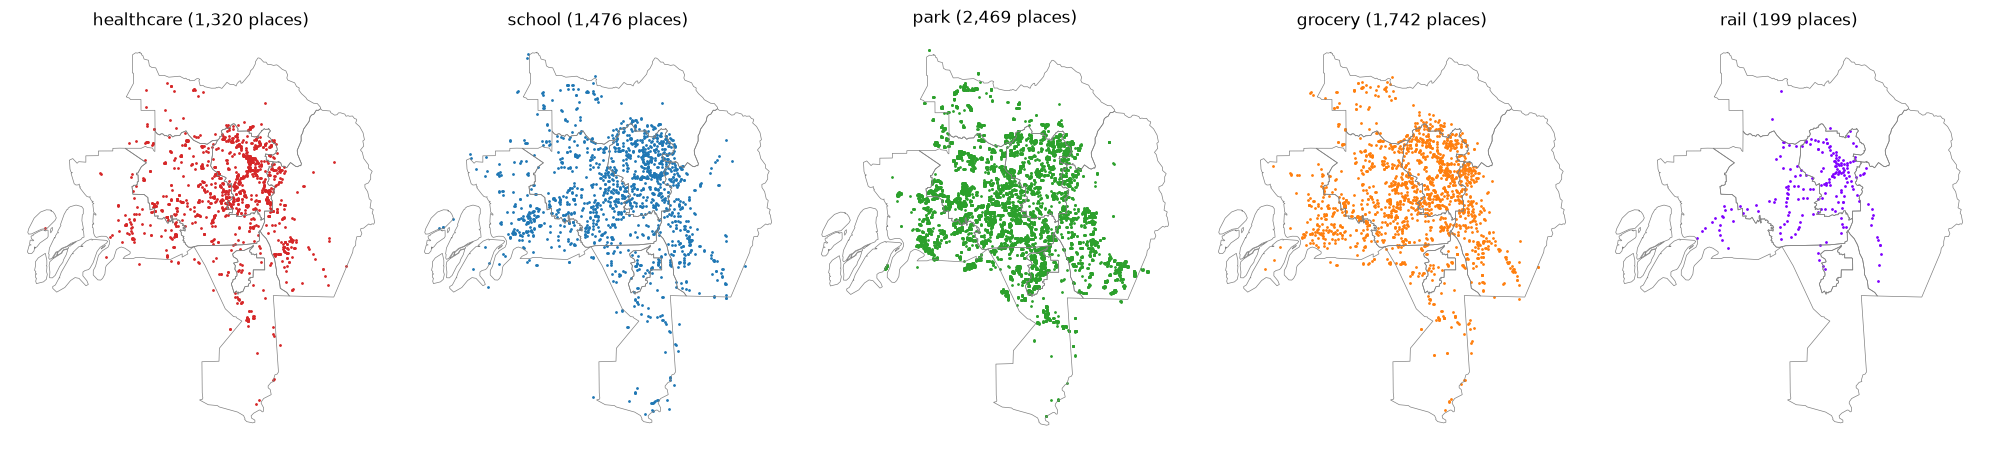

In [12]:
import matplotlib.pyplot as plt

colours = {"healthcare": "#d62728", "school": "#1f77b4", "park": "#2ca02c",
           "grocery": "#ff7f0e", "rail": "#7f00ff"}
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for ax, (cat, c) in zip(axes, colours.items()):
    districts.boundary.plot(ax=ax, color="grey", linewidth=0.5)
    s = out[out["category"] == cat]
    ax.scatter(s["lon"], s["lat"], s=1, color=c)
    ax.set_title(f"{cat} ({s['osm_id'].nunique():,} places)")
    ax.set_axis_off()
plt.tight_layout()
plt.savefig(OUTPUT / "stage2_services_preview.png", dpi=100, bbox_inches="tight")
plt.show()

___
**END**